# What the device costs: quantization, crosstalk and the pixel aperture on an 8 x 8 array

**Question:** How much do phase quantization, pixel crosstalk and the pixel aperture cost a hologram of an 8 x 8 trap array, in light and in uniformity?

- Level: 1, fundamentals.
- Prerequisites: `01-fourier-optics/01-where-the-light-goes`, which introduces the pixel envelope.
- Reading time: about 15 minutes. The notebook runs in about 20 seconds.

## Objectives

A hologram is computed on an ideal screen and displayed on a real one. The ideal screen shows any phase exactly, has pixels that are points, and lets each pixel act alone. A real spatial light modulator rounds the phase to a few hundred levels at best, covers only part of each pixel, lets neighbouring pixels leak into each other, and wobbles in time. Each of these defects has a number, and the notebook measures them one at a time on the same hologram. By the end you can:

- name the four effects of the device model and say what each does to a trap array;
- predict the light lost to quantization from the number of levels, and say where the prediction stops working;
- add the effects one by one and read which of them dominates.

## Setup


The notebook environment is pinned in `notebooks/requirements.txt` and built with `scripts/setup.sh --notebooks`
(`scripts/setup.ps1 -Notebooks` on Windows). This notebook uses two packages, at these exact pins:

```bash
pip install numpy==2.4.6 matplotlib==3.11.2
```

DinHot publishes no package of its own: its methods live in the pipeline folder `data-pipeline/`, and the next cell puts
that folder on the import path and imports the functions the notebook calls.

In [1]:
# the tools, their versions, and the pipeline folder on the import path
import sys
from importlib.metadata import version
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np

ROOT = Path("../../..").resolve()
sys.path.insert(0, str(ROOT / "data-pipeline"))
from pipeline.cases import build
from pipeline.core import score as scoring
from pipeline.io.contract import read_cases
from pipeline.model.holo.core.device import Device, pixel_envelope
from pipeline.model.holo.core.forward import trap_bins
from pipeline.model.holo.core.rng import Rng
from pipeline.model.holo.core.types import Budget
from pipeline.model.holo.methods.baseline import m06_gsw

print("numpy", version("numpy"), "| matplotlib", version("matplotlib"))

numpy 2.4.6 | matplotlib 3.11.2


## Data

The notebook reads case C08 of `data/examples/cases.json`: an 8 x 8 array on a 128 x 128 pixel SLM, with the device parameters of the case.

- Owner: this repository; the case is synthetic, and its crosstalk parameters are those fitted by Schroff et al. (2023).
- Licence class: generated data under the repository's own licence, no third-party dataset.
- File: `data/examples/cases.json`, case C08.

In [2]:
# case C08: an 8 x 8 array on a device with 4-bit phase, crosstalk, a fill factor of 0.85 and flicker
rec = {c["case_id"][:3]: c for c in read_cases(ROOT / "data/examples/cases.json")}["C08"]
setup = build.setup_of(rec)
target = build.target_of(rec)
device_c08 = build.device_of(rec)
print(rec["case_id"], "|", len(target.traps), "traps | SLM", setup.n_pix, "x", setup.n_pix, "pixels")
print(device_c08)

C08_device_limited | 64 traps | SLM 128 x 128 pixels
Device(bit_depth=4, crosstalk=(1.24, 1.8), upsample=3, fill_factor=0.85, flicker_rad=0.05, lut_gamma=1.0)


## Method

### Step 1: a hologram computed for the ideal screen

The device model of the pipeline turns an ideal phase pattern into what a real modulator shows, in this order: the phase is wrapped, rounded to $N = 2^b$ equally spaced levels, passed through the response of the liquid crystal (a straight line in this case), and disturbed by a random flicker of a given rms. The displayed pattern is then upsampled to 3 x 3 samples per pixel, blurred by the crosstalk kernel $K = \mathcal{F}^{-1}\{\exp[-(|k_x|^q + |k_y|^q)/\sigma^q]\}$ with $\sigma = 1.24$ and $q = 1.80$ (Schroff et al., 2023, Methods), transformed, and multiplied by the envelope of the pixel aperture, $\mathrm{sinc}(a x / \lambda f)\,\mathrm{sinc}(a y / \lambda f)$ with $a = \sqrt{\text{fill}}\,p$. The first cell computes the hologram that every later step displays: weighted Gerchberg-Saxton (M06) for 30 iterations on the ideal model.

In [3]:
# the hologram every later step starts from: weighted GS on the ideal model, 30 iterations
res_gsw = m06_gsw.run(setup, target, budget=Budget(30), rng=Rng(1))
ideal = res_gsw.history[-1]
print(f"ideal model: efficiency {ideal['efficiency']:.4f}  "
      f"uniformity {ideal['uniformity']:.4f}  rel. std {ideal['rel_std']:.2f} %")

ideal model: efficiency 0.8014  uniformity 0.9888  rel. std 0.44 %


### Step 2: the pixel aperture, before anything is rounded

The cheapest device in the model, `Device()`, has square pixels that fill the pitch, no quantization, no crosstalk and no flicker. Even this device is not the ideal screen: a pixel of finite width diffracts less light towards the edge of the field, so the traps away from the axis get less. The cell reads the envelope at the 64 trap positions and scores the same hologram through that device with the pipeline's scorer, the one definition that every method is judged by.

In [4]:
# the pixel aperture alone: a device with fill factor 1, no quantization, no crosstalk, no flicker
aperture = Device()
iy, ix = trap_bins(setup, target.traps)
at_traps = pixel_envelope(setup, aperture)[iy, ix]
print(f"envelope over the 64 traps, min and max: {at_traps.min():.4f} {at_traps.max():.4f}")
shown = scoring.score(rec, res_gsw.phi, setup=setup, device=aperture)
print(f"aperture only: efficiency {shown['efficiency']:.4f}  "
      f"uniformity {shown['uniformity']:.4f}  rel. std {shown['rel_std_pct']:.2f} %")

envelope over the 64 traps, min and max: 0.8836 0.9975
aperture only: efficiency 0.7533  uniformity 0.9104  rel. std 4.12 %


The aperture alone already costs light and uniformity: the envelope varies by about 11 percent across the 64 traps, from 0.8836 to 0.9975, and the efficiency falls from 0.8014 to 0.7533 while the relative standard deviation rises from 0.44 to 4.12 percent. Whatever the cells below add is added on top of this floor.

### Step 3: quantization

Rounding the phase to $N$ levels leaves an error that is roughly uniform in $\pm \pi / N$. The mean of $e^{i\epsilon}$ for such an error is $\mathrm{sinc}(1/N) = \sin(\pi/N)/(\pi/N)$, so the light that stays in phase with the ideal field, and reaches the traps, falls by $\mathrm{sinc}^2(1/N)$. That is the first-order efficiency of a stepped phase grating, and the device-model card gives it as the quantization efficiency. The cell displays the same hologram with 8, 6, 4, 3, 2 and 1 bits, and compares the measured efficiency, relative to 8 bits, with the estimate.

In [5]:
# the same hologram displayed with 8, 6, 4, 3, 2 and 1 bits of phase (the pixel aperture stays)
bits = (8, 6, 4, 3, 2, 1)
quant = {b: scoring.score(rec, res_gsw.phi, setup=setup, device=Device(bit_depth=b)) for b in bits}
for b, s in quant.items():
    ratio = s["efficiency"] / quant[8]["efficiency"]
    print(f"{b} bits: efficiency ratio to 8 bits {ratio:.4f} "
          f"(sinc^2(1/N) {np.sinc(1 / 2**b) ** 2:.4f})  rel. std {s['rel_std_pct']:.2f} %")

8 bits: efficiency ratio to 8 bits 1.0000 (sinc^2(1/N) 0.9999)  rel. std 4.12 %
6 bits: efficiency ratio to 8 bits 0.9994 (sinc^2(1/N) 0.9992)  rel. std 4.13 %
4 bits: efficiency ratio to 8 bits 0.9878 (sinc^2(1/N) 0.9872)  rel. std 5.12 %
3 bits: efficiency ratio to 8 bits 0.9523 (sinc^2(1/N) 0.9496)  rel. std 6.38 %
2 bits: efficiency ratio to 8 bits 0.8271 (sinc^2(1/N) 0.8106)  rel. std 21.61 %
1 bits: efficiency ratio to 8 bits 0.8156 (sinc^2(1/N) 0.4053)  rel. std 79.35 %


The figure plots the measured efficiency ratio against the estimate on the left, and the relative standard deviation of the traps on the right.

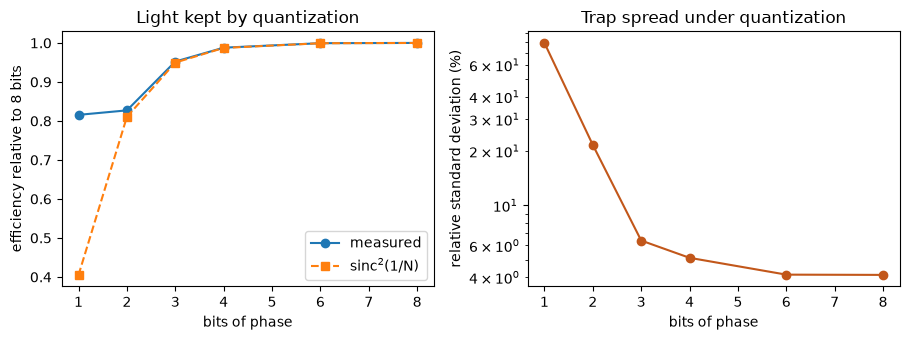

In [6]:
# efficiency ratio against the sinc^2 estimate, and the spread, as the phase loses bits
fig, (a, b) = plt.subplots(1, 2, figsize=(9.2, 3.5))
a.plot(bits, [quant[k]["efficiency"] / quant[8]["efficiency"] for k in bits], "o-", label="measured")
a.plot(bits, [np.sinc(1 / 2**k) ** 2 for k in bits], "s--", label="sinc$^2$(1/N)")
a.set_xlabel("bits of phase")
a.set_ylabel("efficiency relative to 8 bits")
a.set_title("Light kept by quantization")
a.legend()
b.semilogy(bits, [quant[k]["rel_std_pct"] for k in bits], "o-", color="#c2571a")
b.set_xlabel("bits of phase")
b.set_ylabel("relative standard deviation (%)")
b.set_title("Trap spread under quantization")
plt.tight_layout()
plt.show()

The estimate is accurate where quantization is mild: at 4 bits the measured ratio is 0.9878 against 0.9872, at 3 bits 0.9523 against 0.9496, and even at 2 bits 0.8271 against 0.8106. Four bits lose only about 1 percent of the light, so the efficiency is not what makes quantization matter. The spread is: the relative standard deviation rises from 4.12 percent at 8 bits to 5.12 at 4 bits and 6.38 at 3, then jumps to 21.61 at 2 bits and 79.35 at 1 bit, where the traps are no longer equal at all. The 1-bit point is also where the estimate fails, 0.8156 measured against 0.4053 estimated. A binary phase pattern is not a small perturbation of an ideal one, because it writes a mirror image of the array as well, and the sinc estimate describes only the light that stays with the wanted field. The cause of the mismatch at 1 bit was not tested here. The figure shows one hologram on one array; it does not show how the loss would change for a different trap geometry.

### Step 4: all the effects, one added at a time

The device of case C08 has four effects together: 4 bits, crosstalk, a fill factor of 0.85 and a flicker of 0.05 rad. The cell builds the device up in that order, from the aperture alone to the full device of the case, and scores the same hologram through each stage. Because the flicker is random, the pipeline's scorer draws it from a seeded stream tied to the case, so every run sees the same flicker.

In [7]:
# the effects added one by one: aperture, 4 bits, crosstalk, fill factor 0.85, flicker (the device of the case)
stages = {
    "aperture": Device(),
    "+ 4 bits": Device(bit_depth=4),
    "+ crosstalk": Device(bit_depth=4, crosstalk=(1.24, 1.8), upsample=3),
    "+ fill 0.85": Device(bit_depth=4, crosstalk=(1.24, 1.8), upsample=3, fill_factor=0.85),
    "+ flicker": device_c08,
}
stack = {k: scoring.score(rec, res_gsw.phi, setup=setup, device=d) for k, d in stages.items()}
for k, s in stack.items():
    print(f"{k:22s} efficiency {s['efficiency']:.4f}  uniformity {s['uniformity']:.4f}  "
          f"rel. std {s['rel_std_pct']:.2f} %")

aperture               efficiency 0.7533  uniformity 0.9104  rel. std 4.12 %
+ 4 bits               efficiency 0.7441  uniformity 0.8678  rel. std 5.12 %
+ crosstalk            efficiency 0.6952  uniformity 0.7223  rel. std 13.07 %
+ fill 0.85            efficiency 0.7006  uniformity 0.7279  rel. std 12.87 %
+ flicker              efficiency 0.6849  uniformity 0.7028  rel. std 13.99 %


The bars give the relative standard deviation after each added effect, with the dashed line at the value of the ideal model.

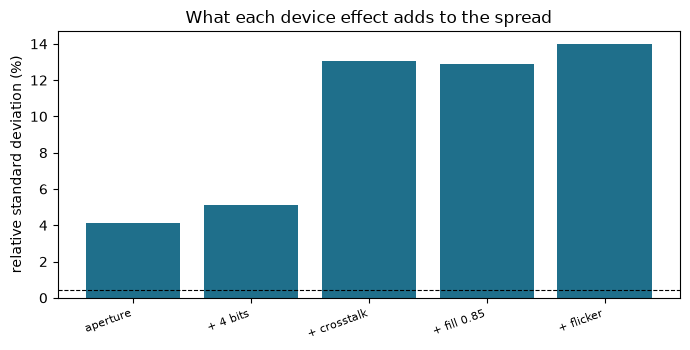

In [8]:
# relative standard deviation of the traps after each added effect
fig, ax = plt.subplots(figsize=(7.0, 3.6))
ax.bar(range(len(stack)), [s["rel_std_pct"] for s in stack.values()], color="#1f6f8b")
ax.set_xticks(range(len(stack)))
ax.set_xticklabels(list(stack), rotation=20, ha="right", fontsize=8)
ax.axhline(ideal["rel_std"], color="k", linewidth=0.8, linestyle="--")
ax.set_ylabel("relative standard deviation (%)")
ax.set_title("What each device effect adds to the spread")
plt.tight_layout()
plt.show()

Crosstalk dominates. Going from 4 bits to 4 bits plus crosstalk raises the spread from 5.12 to 13.07 percent and lowers the efficiency from 0.7441 to 0.6952, a loss of 0.0489 of the light, larger than the whole of the quantization loss. A likely reason is the kernel: with $\sigma = 1.24$ per pixel the phase of one pixel is smeared over its neighbours, which low-passes the hologram, and the high-frequency detail that steers light to the outer traps is the part that goes. The next two stages are small. The fill factor of 0.85 moves the spread slightly down, to 12.87 percent, and the efficiency slightly up, to 0.7006: in the pipeline's model a smaller pixel flattens the envelope and the power lost in the dead area is not charged, as the device module states, so this stage should not be read as a benefit of a real device. The flicker adds about one point of spread, 13.99 percent, with an efficiency of 0.6849, from one seeded draw. The stack ends with the efficiency at 85 percent of the ideal (0.6849 against 0.8014) and the spread about 32 times larger. The figure does not separate the aperture from the others once they interact; the order of the additions changes each step but not the end point.

## Results

**Answer:** The device costs the 8 x 8 array about 15 percent of its light and most of its uniformity, and crosstalk is the effect that matters. Through the full device of case C08 the hologram that has 0.8014 efficiency and a relative standard deviation of 0.44 percent on the ideal screen shows 0.6849 and 13.99 percent. Quantization alone is mild: 4 bits keep 0.9878 of the light, as the estimate $\mathrm{sinc}^2(1/N)$ of 0.9872 predicts, and raise the spread from 4.12 to 5.12 percent; the pixel aperture alone already takes the efficiency from 0.8014 to 0.7533. Crosstalk raises the spread from 5.12 to 13.07 percent.

What the notebook does not show is what a method that knows the device can win back, which the level 3 notebook `06-device-and-aberrations/03-crosstalk-aware-cg-against-cg` measures, or how the loss depends on the geometry of the array.

## Summary

- The device model has four effects: quantization, crosstalk, the pixel aperture and flicker, applied to the phase before the light is computed.
- The aperture alone takes the efficiency of this array from 0.8014 to 0.7533 and sets a floor of 4.12 percent on the spread.
- Quantization costs light as $\mathrm{sinc}^2(1/N)$ down to 2 bits and uniformity from 3 bits down; the estimate fails for a binary pattern.
- Crosstalk is the dominant effect: it adds more spread than quantization, fill factor and flicker together.

## References

- Schroff et al. (2023). Accurate holographic light potentials using pixel crosstalk modelling. Scientific Reports 13, 3252. https://doi.org/10.1038/s41598-023-30296-6
- Di Leonardo, Ianni and Ruocco (2007). Computer generation of optimal holograms for optical trap arrays. Optics Express 15, 1913. https://doi.org/10.1364/OE.15.001913